# Motion-Aware Smart Surveillance System

## Project Overview
This system implements a comprehensive surveillance solution that:
- **Detects motion** in real-time using background subtraction
- **Extracts moving objects** using contour detection
- **Tracks objects** across consecutive frames
- **Classifies objects** based on size, shape, and movement patterns
- **Counts objects** entering/leaving the scene with virtual counting lines
- **Analyzes movement** using edge detection and shape features

### Goals:
1. Real-time motion detection and background subtraction
2. Robust object extraction and contour analysis
3. Multi-object tracking with centroid tracking
4. Edge detection using Canny edge detection
5. Shape analysis using Hough Transform (lines and circles)
6. Intelligent object classification (person, car, small object, unknown)
7. Accurate counting with virtual regions to avoid double-counting
8. Real-time visualization with bounding boxes, labels, and statistics

### Requirements:
- OpenCV (cv2) for computer vision
- NumPy for numerical operations
- Matplotlib for visualization
- Scipy for advanced image processing

## 1. Import Required Libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from collections import defaultdict, deque
from scipy.spatial.distance import cdist
import warnings
warnings.filterwarnings('ignore')

print("✓ All libraries imported successfully")
print(f"OpenCV version: {cv2.__version__}")

✓ All libraries imported successfully
OpenCV version: 4.11.0


## 2. Motion Detection Module

### Purpose:
Detect moving areas in the frame by comparing consecutive frames and using background subtraction techniques.

### Methods:
1. **Frame Differencing**: Compare consecutive frames to find changes
2. **Morphological Operations**: Clean up noise and fill gaps
3. **Thresholding**: Convert to binary image for clear motion regions

In [2]:
class MotionDetector:
    """
    Detects motion in video frames using multiple techniques:
    - Frame differencing for motion detection
    - Morphological operations for noise removal
    - Background subtraction using MOG2 algorithm
    """
    
    def __init__(self, blur_kernel=(21, 21), threshold=30):
        """
        Initialize Motion Detector
        
        Parameters:
        - blur_kernel: Gaussian blur kernel size (must be odd)
        - threshold: Threshold value for binary conversion
        """
        self.blur_kernel = blur_kernel
        self.threshold = threshold
        # MOG2 (Mixture of Gaussians) background subtractor
        self.bg_subtractor = cv2.createBackgroundSubtractorMOG2(
            detectShadows=True
        )
        self.prev_frame = None
    
    def detect_motion(self, frame):
        """
        Detect motion using background subtraction
        
        Steps:
        1. Convert to grayscale
        2. Apply Gaussian blur to reduce noise
        3. Use MOG2 background subtractor
        4. Apply morphological operations
        5. Return binary motion mask
        
        Returns:
        - motion_mask: Binary image where white = motion, black = no motion
        """
        # Convert to grayscale
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        # Apply Gaussian blur to reduce noise
        # Larger kernel = more smoothing = less sensitive to small changes
        blurred = cv2.GaussianBlur(gray, self.blur_kernel, 0)
        
        # Background subtraction using MOG2 algorithm
        # This algorithm models the background as a mixture of Gaussians
        # It's robust to gradual changes and shadows
        fg_mask = self.bg_subtractor.apply(blurred)
        
        # Remove shadows (MOG2 marks shadows as gray, we only want foreground)
        _, motion_mask = cv2.threshold(fg_mask, 200, 255, cv2.THRESH_BINARY)
        
        # Morphological operations to clean up the mask
        # Step 1: Erosion removes small white noise (false positives)
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
        eroded = cv2.erode(motion_mask, kernel, iterations=2)
        
        # Step 2: Dilation fills gaps in moving objects (false negatives)
        dilated = cv2.dilate(eroded, kernel, iterations=2)
        
        # Step 3: Closing (dilation followed by erosion) fills small holes
        kernel_large = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))
        closed = cv2.morphologyEx(dilated, cv2.MORPH_CLOSE, kernel_large, iterations=2)
        
        return closed
    
    def get_motion_contours(self, motion_mask, min_area=500):
        """
        Extract contours of moving objects from motion mask
        
        Parameters:
        - motion_mask: Binary image from detect_motion()
        - min_area: Minimum contour area to consider as motion (filters noise)
        
        Returns:
        - contours: List of contour arrays
        """
        # Find all contours in the motion mask
        # Contours are curves joining all continuous points having same color/intensity
        contours, _ = cv2.findContours(motion_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        
        # Filter contours by minimum area
        valid_contours = [cnt for cnt in contours if cv2.contourArea(cnt) > min_area]
        
        return valid_contours

print("✓ MotionDetector class created successfully")

✓ MotionDetector class created successfully


## 3. Edge Detection and Shape Analysis Module

### Purpose:
Analyze the shape of detected objects using edge detection (Canny) and shape descriptors.

### Techniques:
1. **Canny Edge Detection**: Finds edges within objects
2. **Contour Moments**: Computes shape properties (area, centroid, aspect ratio)
3. **Hu Moments**: Shape descriptors invariant to rotation, scale, translation
4. **Circularity**: Measures how circular an object is

In [3]:
class EdgeDetector:
    """
    Performs edge detection and shape analysis on objects
    """
    
    @staticmethod
    def detect_edges_canny(frame, sigma=0.33):
        """
        Apply Canny edge detection with automatic threshold calculation
        
        Canny Edge Detection Steps:
        1. Smooth image with Gaussian blur
        2. Compute gradient magnitude and direction
        3. Non-maximum suppression (thin edges)
        4. Double thresholding (weak and strong edges)
        5. Edge tracking by hysteresis
        
        Parameters:
        - frame: Input image (BGR or grayscale)
        - sigma: Used for automatic threshold computation
        
        Returns:
        - edges: Binary image with detected edges
        """
        # Convert to grayscale if needed
        if len(frame.shape) == 3:
            gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        else:
            gray = frame
        
        # Automatic threshold calculation based on image median
        # Prevents threshold selection bias
        median = np.median(gray)
        lower = int(max(0, (1.0 - sigma) * median))
        upper = int(min(255, (1.0 + sigma) * median))
        
        # Apply Canny edge detection
        # Lower threshold: edges with gradient below this are discarded
        # Upper threshold: edges with gradient above this are kept
        edges = cv2.Canny(gray, lower, upper)
        
        return edges
    
    @staticmethod
    def get_shape_properties(contour):
        """
        Calculate shape properties of a contour
        
        Returns dictionary with:
        - area: Contour area
        - perimeter: Contour perimeter
        - centroid: Center point (cx, cy)
        - bounding_box: (x, y, w, h)
        - aspect_ratio: width/height
        - circularity: 4π*area / perimeter² (1 = circle, <1 = elongated)
        - solidity: area / convex_hull_area
        - hu_moments: Shape descriptors invariant to rotation/scale/translation
        """
        # Area: Number of pixels inside contour
        area = cv2.contourArea(contour)
        
        if area == 0:
            return None
        
        # Perimeter: Arc length of contour
        perimeter = cv2.arcLength(contour, True)
        
        # Moments: Used to calculate centroid and other properties
        M = cv2.moments(contour)
        if M['m00'] == 0:
            return None
        
        # Centroid: Center of mass of contour
        cx = int(M['m10'] / M['m00'])
        cy = int(M['m01'] / M['m00'])
        
        # Bounding rectangle
        x, y, w, h = cv2.boundingRect(contour)
        
        # Aspect ratio: How elongated the object is
        aspect_ratio = float(w) / h if h != 0 else 0
        
        # Circularity: How circular the object is (0-1, 1=perfect circle)
        if perimeter == 0:
            circularity = 0
        else:
            circularity = 4 * np.pi * area / (perimeter ** 2)
        
        # Solidity: Ratio of area to convex hull area
        hull = cv2.convexHull(contour)
        hull_area = cv2.contourArea(hull)
        solidity = area / hull_area if hull_area > 0 else 0
        
        # Hu Moments: Invariant shape descriptors
        hu_moments = cv2.HuMoments(contour).flatten()
        
        return {
            'area': area,
            'perimeter': perimeter,
            'centroid': (cx, cy),
            'bounding_box': (x, y, w, h),
            'aspect_ratio': aspect_ratio,
            'circularity': circularity,
            'solidity': solidity,
            'hu_moments': hu_moments
        }

print("✓ EdgeDetector class created successfully")

✓ EdgeDetector class created successfully


## 4. Hough Transform Module

### Purpose:
Detect lines and circles within objects to understand their structure.

### Techniques:
1. **Hough Line Transform**: Detects straight lines in edges
2. **Hough Circle Transform**: Detects circular objects

In [4]:
class HoughTransformAnalyzer:
    """
    Analyzes object structure using Hough transforms for lines and circles
    """
    
    @staticmethod
    def detect_lines(edges, min_line_length=30, max_line_gap=10):
        """
        Detect lines in image using Probabilistic Hough Line Transform
        
        Hough Line Transform:
        1. Convert image coordinates (x,y) to parameter space (ρ, θ)
        2. Each line in image space becomes a point in parameter space
        3. Count accumulator cells to find peaks = detected lines
        
        Parameters:
        - edges: Binary edge image from Canny
        - min_line_length: Minimum line length to consider
        - max_line_gap: Maximum gap between line segments to connect them
        
        Returns:
        - lines: Array of detected lines as [[x1, y1, x2, y2], ...]
        """
        if edges is None:
            return None
        
        # Probabilistic Hough Line Transform
        # Returns specific line segments instead of infinite lines
        lines = cv2.HoughLinesP(
            edges,
            rho=1,              # Distance resolution (pixels)
            theta=np.pi/180,    # Angle resolution (degrees)
            threshold=20,       # Minimum votes needed to detect a line
            minLineLength=min_line_length,
            maxLineGap=max_line_gap
        )
        
        return lines
    
    @staticmethod
    def detect_circles(edges, min_radius=5, max_radius=100):
        """
        Detect circles in image using Hough Circle Transform
        
        Hough Circle Transform:
        1. For each edge point, draw all possible circles passing through it
        2. In parameter space (center_x, center_y, radius), this creates curves
        3. Find peaks in accumulator array = circle centers and radii
        
        Parameters:
        - edges: Binary edge image from Canny
        - min_radius: Minimum circle radius
        - max_radius: Maximum circle radius
        
        Returns:
        - circles: Array of detected circles as [center_x, center_y, radius]
        """
        if edges is None:
            return None
        
        # Convert to 8-bit image if needed
        if edges.dtype != np.uint8:
            edges = cv2.convertScaleAbs(edges, alpha=255/edges.max())
        
        # Hough Circle Transform
        circles = cv2.HoughCircles(
            edges,
            cv2.HOUGH_GRADIENT,
            dp=1,                    # Inverse ratio of accumulator resolution
            minDist=30,              # Minimum distance between circle centers
            param1=50,               # Upper threshold for Canny edge detection
            param2=30,               # Accumulator threshold
            minRadius=min_radius,
            maxRadius=max_radius
        )
        
        if circles is not None:
            circles = circles[0]
        
        return circles
    
    @staticmethod
    def analyze_structure(lines, circles):
        """
        Analyze detected lines and circles to understand object structure
        
        Returns dictionary with:
        - line_count: Number of detected lines
        - circle_count: Number of detected circles
        - avg_line_length: Average length of detected lines
        - has_circular_parts: Boolean if circles detected
        - has_linear_parts: Boolean if lines detected
        """
        structure = {
            'line_count': 0,
            'circle_count': 0,
            'avg_line_length': 0,
            'has_circular_parts': False,
            'has_linear_parts': False
        }
        
        if lines is not None:
            structure['line_count'] = len(lines)
            structure['has_linear_parts'] = True
            # Calculate average line length
            lengths = []
            for line in lines:
                x1, y1, x2, y2 = line[0]
                length = np.sqrt((x2-x1)**2 + (y2-y1)**2)
                lengths.append(length)
            if lengths:
                structure['avg_line_length'] = np.mean(lengths)
        
        if circles is not None:
            structure['circle_count'] = len(circles)
            structure['has_circular_parts'] = True
        
        return structure

print("✓ HoughTransformAnalyzer class created successfully")

✓ HoughTransformAnalyzer class created successfully


## 5. Object Classification Module

### Purpose:
Classify detected objects based on size, shape, and movement characteristics.

### Classification Rules:
- **Person**: Medium size, specific aspect ratio, medium speed
- **Car**: Large size, specific aspect ratio, moderate speed  
- **Small Object**: Small area, fast movement
- **Unknown**: Doesn't match any category

In [5]:
class ObjectClassifier:
    """
    Classifies detected objects based on size, shape, and movement
    """
    
    @staticmethod
    def classify_object(shape_props, movement_speed=None, frame_shape=None):
        """
        Classify object as person, car, small_object, or unknown
        
        Classification Logic:
        1. Calculate normalized area relative to frame
        2. Use aspect ratio and area to determine object type
        3. Consider movement speed if available
        
        Parameters:
        - shape_props: Dictionary from EdgeDetector.get_shape_properties()
        - movement_speed: Speed of object movement (optional)
        - frame_shape: (height, width) of frame for normalization
        
        Returns:
        - object_type: String ('person', 'car', 'small_object', 'unknown')
        - confidence: Float 0-1 indicating classification confidence
        """
        if shape_props is None:
            return 'unknown', 0.0
        
        area = shape_props['area']
        aspect_ratio = shape_props['aspect_ratio']
        circularity = shape_props['circularity']
        
        # Normalize area relative to frame
        if frame_shape:
            frame_area = frame_shape[0] * frame_shape[1]
            area_ratio = area / frame_area
        else:
            area_ratio = area / 10000  # Assume typical frame
        
        # Classification Rules
        # Rule 1: CAR - Large object with specific aspect ratio
        if 0.04 < area_ratio < 0.4 and 0.5 < aspect_ratio < 3.0:
            confidence = 0.9 if 0.8 < aspect_ratio < 2.5 else 0.7
            return 'car', confidence
        
        # Rule 2: PERSON - Medium size, aspect ratio 0.3-0.7 (taller than wide)
        elif 0.01 < area_ratio < 0.15 and 0.25 < aspect_ratio < 0.8:
            confidence = 0.9 if 0.35 < aspect_ratio < 0.7 else 0.7
            return 'person', confidence
        
        # Rule 3: SMALL OBJECT - Small area, can be any shape
        elif area_ratio < 0.01 and area > 100:
            confidence = 0.85
            return 'small_object', confidence
        
        # Rule 4: Alternative person detection - tall objects
        elif area_ratio < 0.2 and aspect_ratio < 0.4:
            confidence = 0.6
            return 'person', confidence
        
        # Rule 5: Alternative car detection - horizontal objects
        elif 0.02 < area_ratio < 0.3 and aspect_ratio > 1.5:
            confidence = 0.6
            return 'car', confidence
        
        # Default: Unknown object
        return 'unknown', 0.5
    
    @staticmethod
    def get_object_color(object_type):
        """
        Get color for drawing based on object type
        Returns BGR tuple
        """
        colors = {
            'person': (0, 255, 0),        # Green
            'car': (0, 0, 255),           # Red
            'small_object': (255, 255, 0), # Cyan
            'unknown': (128, 128, 128)    # Gray
        }
        return colors.get(object_type, (128, 128, 128))

print("✓ ObjectClassifier class created successfully")

✓ ObjectClassifier class created successfully


## 6. Object Tracking Module

### Purpose:
Track objects across consecutive frames to maintain object identity and calculate movement.

### Algorithm: Centroid Tracking
1. Calculate centroid of each detected object
2. Match centroids across frames using distance threshold
3. Maintain object IDs across frames
4. Calculate movement speed and direction

In [6]:
class ObjectTracker:
    """
    Tracks objects across frames using centroid tracking algorithm
    """
    
    def __init__(self, max_distance=50, max_frames_without_detection=10):
        """
        Initialize tracker
        
        Parameters:
        - max_distance: Maximum distance to match centroids across frames
        - max_frames_without_detection: Remove track if not detected for N frames
        """
        self.objects = {}  # {object_id: {'centroid_history': deque, 'frames_since_seen': int}}
        self.next_object_id = 0
        self.max_distance = max_distance
        self.max_frames_without_detection = max_frames_without_detection
    
    def update(self, centroids, shapes_data=None):
        """
        Update tracker with new frame's detections
        
        Algorithm (Centroid Tracking):
        1. If no objects tracked yet, create new tracks for all centroids
        2. If objects tracked, compute pairwise distances between old and new centroids
        3. Match centroids based on closest distance (if < max_distance)
        4. Unmated centroids become new objects
        5. Unmated objects are marked as lost
        
        Parameters:
        - centroids: List of (x, y) centroid positions from current frame
        - shapes_data: List of shape property dicts (optional)
        
        Returns:
        - objects: Updated tracking dictionary
        """
        # Case 1: First frame, no objects tracked yet
        if len(self.objects) == 0:
            for i, centroid in enumerate(centroids):
                self.objects[self.next_object_id] = {
                    'centroid_history': deque(maxlen=30),
                    'frames_since_seen': 0,
                    'shape_data': shapes_data[i] if shapes_data else None
                }
                self.objects[self.next_object_id]['centroid_history'].append(centroid)
                self.next_object_id += 1
        
        # Case 2: Update existing tracks with new detections
        else:
            # Get old centroids
            old_centroids = [self.objects[obj_id]['centroid_history'][-1] 
                             for obj_id in sorted(self.objects.keys())]
            
            # Compute pairwise distances between old and new centroids
            if len(old_centroids) > 0 and len(centroids) > 0:
                distances = cdist(old_centroids, centroids)
            else:
                distances = np.array([])
            
            # Find matches
            matched_old = set()
            matched_new = set()
            
            # Greedy matching: iteratively match closest pairs
            while distances.size > 0:
                # Find minimum distance
                min_idx = np.unravel_index(distances.argmin(), distances.shape)
                old_idx, new_idx = min_idx
                
                # Check if distance is within threshold
                if distances[min_idx] < self.max_distance:
                    # Match found
                    old_obj_id = sorted(self.objects.keys())[old_idx]
                    matched_old.add(old_idx)
                    matched_new.add(new_idx)
                    
                    # Update track
                    self.objects[old_obj_id]['centroid_history'].append(centroids[new_idx])
                    self.objects[old_obj_id]['frames_since_seen'] = 0
                    if shapes_data:
                        self.objects[old_obj_id]['shape_data'] = shapes_data[new_idx]
                
                # Remove matched row and column
                distances = np.delete(distances, old_idx, axis=0)
                distances = np.delete(distances, new_idx, axis=1)
            
            # Handle unmatched objects (lost tracks)
            for old_idx, obj_id in enumerate(sorted(self.objects.keys())):
                if old_idx not in matched_old:
                    self.objects[obj_id]['frames_since_seen'] += 1
            
            # Handle unmatched centroids (new objects)
            for new_idx, centroid in enumerate(centroids):
                if new_idx not in matched_new:
                    self.objects[self.next_object_id] = {
                        'centroid_history': deque(maxlen=30),
                        'frames_since_seen': 0,
                        'shape_data': shapes_data[new_idx] if shapes_data else None
                    }
                    self.objects[self.next_object_id]['centroid_history'].append(centroid)
                    self.next_object_id += 1
        
        # Remove lost tracks
        self.objects = {
            obj_id: obj for obj_id, obj in self.objects.items()
            if obj['frames_since_seen'] <= self.max_frames_without_detection
        }
        
        return self.objects
    
    def get_current_centroid(self, object_id):
        """
        Get current centroid of tracked object
        """
        if object_id in self.objects:
            centroid_history = self.objects[object_id]['centroid_history']
            if len(centroid_history) > 0:
                return centroid_history[-1]
        return None
    
    def get_movement_vector(self, object_id, frames_back=5):
        """
        Calculate movement vector (displacement) of object
        
        Parameters:
        - object_id: ID of object to track
        - frames_back: How many frames back to calculate displacement
        
        Returns:
        - (dx, dy): Displacement in x and y
        - speed: Magnitude of displacement
        """
        if object_id not in self.objects:
            return (0, 0), 0
        
        history = self.objects[object_id]['centroid_history']
        
        if len(history) < 2:
            return (0, 0), 0
        
        # Calculate displacement over last N frames
        frames_back = min(frames_back, len(history) - 1)
        current = history[-1]
        past = history[-frames_back-1]
        
        dx = current[0] - past[0]
        dy = current[1] - past[1]
        speed = np.sqrt(dx**2 + dy**2)
        
        return (dx, dy), speed

print("✓ ObjectTracker class created successfully")

✓ ObjectTracker class created successfully


## 7. Object Counting Module

### Purpose:
Count objects entering/leaving the scene using virtual counting lines/regions.

### Algorithm:
1. Define virtual counting line(s) in the frame
2. Track when objects cross the line
3. Count direction of crossing to track entering/leaving
4. Avoid double-counting by tracking crossing history

In [7]:
class ObjectCounter:
    """
    Counts objects entering/leaving scene using virtual counting regions
    """
    
    def __init__(self, frame_shape, line_position='middle', line_direction='horizontal'):
        """
        Initialize counter
        
        Parameters:
        - frame_shape: (height, width) of frame
        - line_position: 'top', 'middle', 'bottom', or integer position
        - line_direction: 'horizontal' or 'vertical'
        """
        self.frame_shape = frame_shape
        self.line_direction = line_direction
        
        # Set counting line position
        if line_direction == 'horizontal':
            height = frame_shape[0]
            if line_position == 'top':
                self.line_pos = int(height * 0.25)
            elif line_position == 'middle':
                self.line_pos = int(height * 0.5)
            elif line_position == 'bottom':
                self.line_pos = int(height * 0.75)
            else:
                self.line_pos = int(line_position)
        else:  # vertical
            width = frame_shape[1]
            if line_position == 'top':
                self.line_pos = int(width * 0.25)
            elif line_position == 'middle':
                self.line_pos = int(width * 0.5)
            elif line_position == 'bottom':
                self.line_pos = int(width * 0.75)
            else:
                self.line_pos = int(line_position)
        
        # Tracking which objects have crossed the line
        # {object_id: {'last_position': value, 'crossed': bool, 'direction': 'up'/'down'/'left'/'right'}}
        self.object_crossings = {}
        
        # Counters
        self.count_up = 0      # Objects crossing upward or leftward
        self.count_down = 0    # Objects crossing downward or rightward
    
    def update_counts(self, tracked_objects):
        """
        Update counting based on current tracked objects
        
        Algorithm:
        1. For each tracked object, get current position
        2. Check if position crosses the counting line
        3. If crossing detected and not already counted, increment counter
        4. Update crossing history to avoid double-counting
        
        Parameters:
        - tracked_objects: Dictionary from ObjectTracker.update()
        """
        for obj_id, obj_data in tracked_objects.items():
            centroid = obj_data['centroid_history'][-1] if obj_data['centroid_history'] else None
            
            if centroid is None:
                continue
            
            # Get current position based on line direction
            if self.line_direction == 'horizontal':
                current_pos = centroid[1]  # y-coordinate
            else:  # vertical
                current_pos = centroid[0]  # x-coordinate
            
            # First time seeing this object
            if obj_id not in self.object_crossings:
                self.object_crossings[obj_id] = {
                    'last_position': current_pos,
                    'crossed': False,
                    'direction': None
                }
            
            # Check if object crossed the line
            last_pos = self.object_crossings[obj_id]['last_position']
            
            # Detect crossing
            crossed_upward = (last_pos >= self.line_pos) and (current_pos < self.line_pos)
            crossed_downward = (last_pos < self.line_pos) and (current_pos >= self.line_pos)
            
            # Count crossing (only once per object)
            if not self.object_crossings[obj_id]['crossed']:
                if crossed_upward:
                    self.count_up += 1
                    self.object_crossings[obj_id]['crossed'] = True
                    self.object_crossings[obj_id]['direction'] = 'up'
                elif crossed_downward:
                    self.count_down += 1
                    self.object_crossings[obj_id]['crossed'] = True
                    self.object_crossings[obj_id]['direction'] = 'down'
            
            # Update position
            self.object_crossings[obj_id]['last_position'] = current_pos
        
        # Clean up objects that are no longer tracked
        self.object_crossings = {
            obj_id: data for obj_id, data in self.object_crossings.items()
            if obj_id in tracked_objects
        }
    
    def get_counting_line_coords(self):
        """
        Get coordinates of counting line for drawing
        
        Returns:
        - (point1, point2): Two points defining the counting line
        """
        if self.line_direction == 'horizontal':
            p1 = (0, self.line_pos)
            p2 = (self.frame_shape[1], self.line_pos)
        else:  # vertical
            p1 = (self.line_pos, 0)
            p2 = (self.line_pos, self.frame_shape[0])
        
        return p1, p2

print("✓ ObjectCounter class created successfully")

✓ ObjectCounter class created successfully


## 8. Main Surveillance System Integration

### Purpose:
Integrate all modules into a complete surveillance system that processes video frames in real-time.

In [8]:
class SurveillanceSystem:
    """
    Main surveillance system that integrates all modules:
    - Motion detection
    - Edge detection
    - Object tracking
    - Object classification
    - Object counting
    """
    
    def __init__(self, video_source=0, frame_width=640, frame_height=480):
        """
        Initialize Surveillance System
        
        Parameters:
        - video_source: 0 for webcam, or path to video file
        - frame_width: Desired frame width
        - frame_height: Desired frame height
        """
        # Initialize all modules
        self.motion_detector = MotionDetector(blur_kernel=(21, 21), threshold=30)
        self.tracker = ObjectTracker(max_distance=50, max_frames_without_detection=10)
        self.classifier = ObjectClassifier()
        self.counter = ObjectCounter(
            frame_shape=(frame_height, frame_width),
            line_position='middle',
            line_direction='horizontal'
        )
        
        # Video source
        self.video_source = video_source
        self.frame_width = frame_width
        self.frame_height = frame_height
        
        # Statistics
        self.frame_count = 0
        self.fps = 0
        self.object_stats = defaultdict(int)
    
    def process_frame(self, frame):
        """
        Process a single frame through the entire pipeline
        
        Pipeline:
        1. Resize frame to standard size
        2. Detect motion using background subtraction
        3. Extract contours from motion regions
        4. Calculate shape properties for each contour
        5. Detect edges using Canny
        6. Detect lines and circles using Hough transform
        7. Classify objects based on shape
        8. Track objects across frames
        9. Update object counters
        
        Returns:
        - frame: Annotated frame
        - detections: List of detected objects with properties
        """
        # Resize frame
        frame = cv2.resize(frame, (self.frame_width, self.frame_height))
        self.frame_count += 1
        
        # Step 1: Motion Detection
        motion_mask = self.motion_detector.detect_motion(frame)
        
        # Step 2: Extract contours
        contours = self.motion_detector.get_motion_contours(motion_mask, min_area=500)
        
        # Prepare data for tracking
        centroids = []
        shapes_data = []
        detections = []
        
        # Step 3: Process each detected object
        for contour in contours:
            # Get shape properties
            shape_props = EdgeDetector.get_shape_properties(contour)
            
            if shape_props is None:
                continue
            
            centroids.append(shape_props['centroid'])
            shapes_data.append(shape_props)
            
            # Extract ROI around object
            x, y, w, h = shape_props['bounding_box']
            roi = frame[max(0, y):min(self.frame_height, y+h), 
                        max(0, x):min(self.frame_width, x+w)]
            
            # Edge detection
            edges = EdgeDetector.detect_edges_canny(roi)
            
            # Hough transform
            lines = HoughTransformAnalyzer.detect_lines(edges)
            circles = HoughTransformAnalyzer.detect_circles(edges)
            structure = HoughTransformAnalyzer.analyze_structure(lines, circles)
            
            # Classification
            object_type, confidence = self.classifier.classify_object(
                shape_props, 
                frame_shape=(self.frame_height, self.frame_width)
            )
            
            # Store detection info
            detection = {
                'contour': contour,
                'shape_props': shape_props,
                'object_type': object_type,
                'confidence': confidence,
                'structure': structure,
                'roi': roi
            }
            detections.append(detection)
        
        # Step 4: Track objects
        tracked_objects = self.tracker.update(centroids, shapes_data)
        
        # Step 5: Update counters
        self.counter.update_counts(tracked_objects)
        
        # Step 6: Draw visualization
        frame_annotated = self._draw_annotations(frame, tracked_objects, detections)
        
        return frame_annotated, tracked_objects, detections
    
    def _draw_annotations(self, frame, tracked_objects, detections):
        """
        Draw all annotations on frame:
        - Bounding boxes with object type
        - Tracking lines
        - Counting line
        - Statistics
        """
        frame_display = frame.copy()
        
        # Draw counting line
        p1, p2 = self.counter.get_counting_line_coords()
        cv2.line(frame_display, p1, p2, (0, 255, 255), 2)
        cv2.putText(frame_display, "Counting Line", (p1[0] + 10, p1[1] - 10),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 1)
        
        # Draw tracked objects
        for obj_id, obj_data in tracked_objects.items():
            # Get current centroid
            centroid = obj_data['centroid_history'][-1]
            
            # Get object type from detection (if available)
            object_type = 'unknown'
            color = (128, 128, 128)
            
            for detection in detections:
                if np.allclose(detection['shape_props']['centroid'], centroid, atol=5):
                    object_type = detection['object_type']
                    break
            
            color = ObjectClassifier.get_object_color(object_type)
            
            # Draw centroid
            cv2.circle(frame_display, centroid, 4, color, -1)
            
            # Draw ID
            cv2.putText(frame_display, f"ID:{obj_id}", 
                       (centroid[0] + 10, centroid[1] - 10),
                       cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
            
            # Draw tracking history
            history = obj_data['centroid_history']
            if len(history) > 1:
                pts = np.array(list(history), dtype=np.int32)
                cv2.polylines(frame_display, [pts], False, color, 2)
            
            # Draw bounding box
            if obj_data['shape_data']:
                x, y, w, h = obj_data['shape_data']['bounding_box']
                cv2.rectangle(frame_display, (x, y), (x+w, y+h), color, 2)
                
                # Draw object type and confidence
                label = f"{object_type}"
                cv2.putText(frame_display, label, (x, y - 5),
                           cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 2)
        
        # Draw statistics
        self._draw_statistics(frame_display)
        
        return frame_display
    
    def _draw_statistics(self, frame):
        """
        Draw statistics on frame
        """
        # Frame information
        cv2.putText(frame, f"Frame: {self.frame_count}", (10, 30),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        
        # Object counters
        cv2.putText(frame, f"Entered: {self.counter.count_up}", (10, 70),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)
        cv2.putText(frame, f"Exited: {self.counter.count_down}", (10, 110),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 0, 255), 2)
        
        # Active objects
        active_objects = len(self.tracker.objects)
        cv2.putText(frame, f"Active Objects: {active_objects}", (10, 150),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2)
        
        # Object type breakdown
        y_offset = 190
        cv2.putText(frame, "Object Types:", (10, y_offset),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1)
        
        obj_types = defaultdict(int)
        for obj_data in self.tracker.objects.values():
            obj_types['total'] += 1
        
        y_offset += 25
        cv2.putText(frame, f"  Total: {obj_types['total']}", (10, y_offset),
                   cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1)

print("✓ SurveillanceSystem class created successfully")

✓ SurveillanceSystem class created successfully


## 9. Demo: Process Sample Frame from Webcam

This section demonstrates the system working on frames captured from your webcam.

In [9]:
def capture_and_process_webcam(num_frames=5):
    """
    Capture frames from webcam and process them through the surveillance system
    
    Parameters:
    - num_frames: Number of frames to capture and process
    """
    print("\n" + "="*60)
    print("SURVEILLANCE SYSTEM DEMO")
    print("="*60)
    
    # Initialize webcam
    cap = cv2.VideoCapture(0)
    
    if not cap.isOpened():
        print("❌ Error: Cannot open webcam")
        return
    
    # Set camera properties
    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 640)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 480)
    cap.set(cv2.CAP_PROP_FPS, 30)
    
    # Initialize surveillance system
    surveillance = SurveillanceSystem(frame_width=640, frame_height=480)
    
    print("\n✓ Surveillance system initialized")
    print(f"✓ Processing {num_frames} frames...\n")
    
    frames_processed = []
    
    for frame_idx in range(num_frames):
        ret, frame = cap.read()
        
        if not ret:
            print(f" Error reading frame {frame_idx}")
            break
        
        # Process frame
        frame_annotated, tracked_objects, detections = surveillance.process_frame(frame)
        frames_processed.append({
            'frame': frame_annotated,
            'tracked_objects': tracked_objects,
            'detections': detections
        })
        
        # Print statistics
        print(f"\nFrame {frame_idx + 1}:")
        print(f"  Objects detected: {len(detections)}")
        print(f"  Objects tracked: {len(tracked_objects)}")
        print(f"  Entered: {surveillance.counter.count_up}")
        print(f"  Exited: {surveillance.counter.count_down}")
        
        # Print detection details
        for i, detection in enumerate(detections):
            print(f"    Detection {i+1}: {detection['object_type']} (confidence: {detection['confidence']:.2f})")
            print(f"      Area: {detection['shape_props']['area']:.0f} px")
            print(f"      Aspect ratio: {detection['shape_props']['aspect_ratio']:.2f}")
            print(f"      Lines detected: {detection['structure']['line_count']}")
            print(f"      Circles detected: {detection['structure']['circle_count']}")
    
    cap.release()
    
    print("\n" + "="*60)
    print("DEMO COMPLETE")
    print("="*60)
    
    return frames_processed, surveillance

# Run demo
print("Starting webcam capture in 2 seconds...")
import time
time.sleep(2)

frames_data, system = capture_and_process_webcam(num_frames=5)

Starting webcam capture in 2 seconds...



SURVEILLANCE SYSTEM DEMO

✓ Surveillance system initialized
✓ Processing 5 frames...


Frame 1:
  Objects detected: 5
  Objects tracked: 5
  Entered: 0
  Exited: 0
    Detection 1: person (confidence: 0.90)
      Area: 16868 px
      Aspect ratio: 0.40
      Lines detected: 15
      Circles detected: 0
    Detection 2: car (confidence: 0.90)
      Area: 44481 px
      Aspect ratio: 1.71
      Lines detected: 380
      Circles detected: 46
    Detection 3: person (confidence: 0.70)
      Area: 8298 px
      Aspect ratio: 0.25
      Lines detected: 133
      Circles detected: 17
    Detection 4: small_object (confidence: 0.85)
      Area: 2903 px
      Aspect ratio: 0.94
      Lines detected: 28
      Circles detected: 3
    Detection 5: car (confidence: 0.90)
      Area: 18940 px
      Aspect ratio: 1.41
      Lines detected: 347
      Circles detected: 36

Frame 2:
  Objects detected: 5
  Objects tracked: 10
  Entered: 0
  Exited: 0
    Detection 1: small_object (confidence: 0.85)
   

## 10. Display Processed Frames

Display the annotated frames with bounding boxes, tracking lines, and statistics.

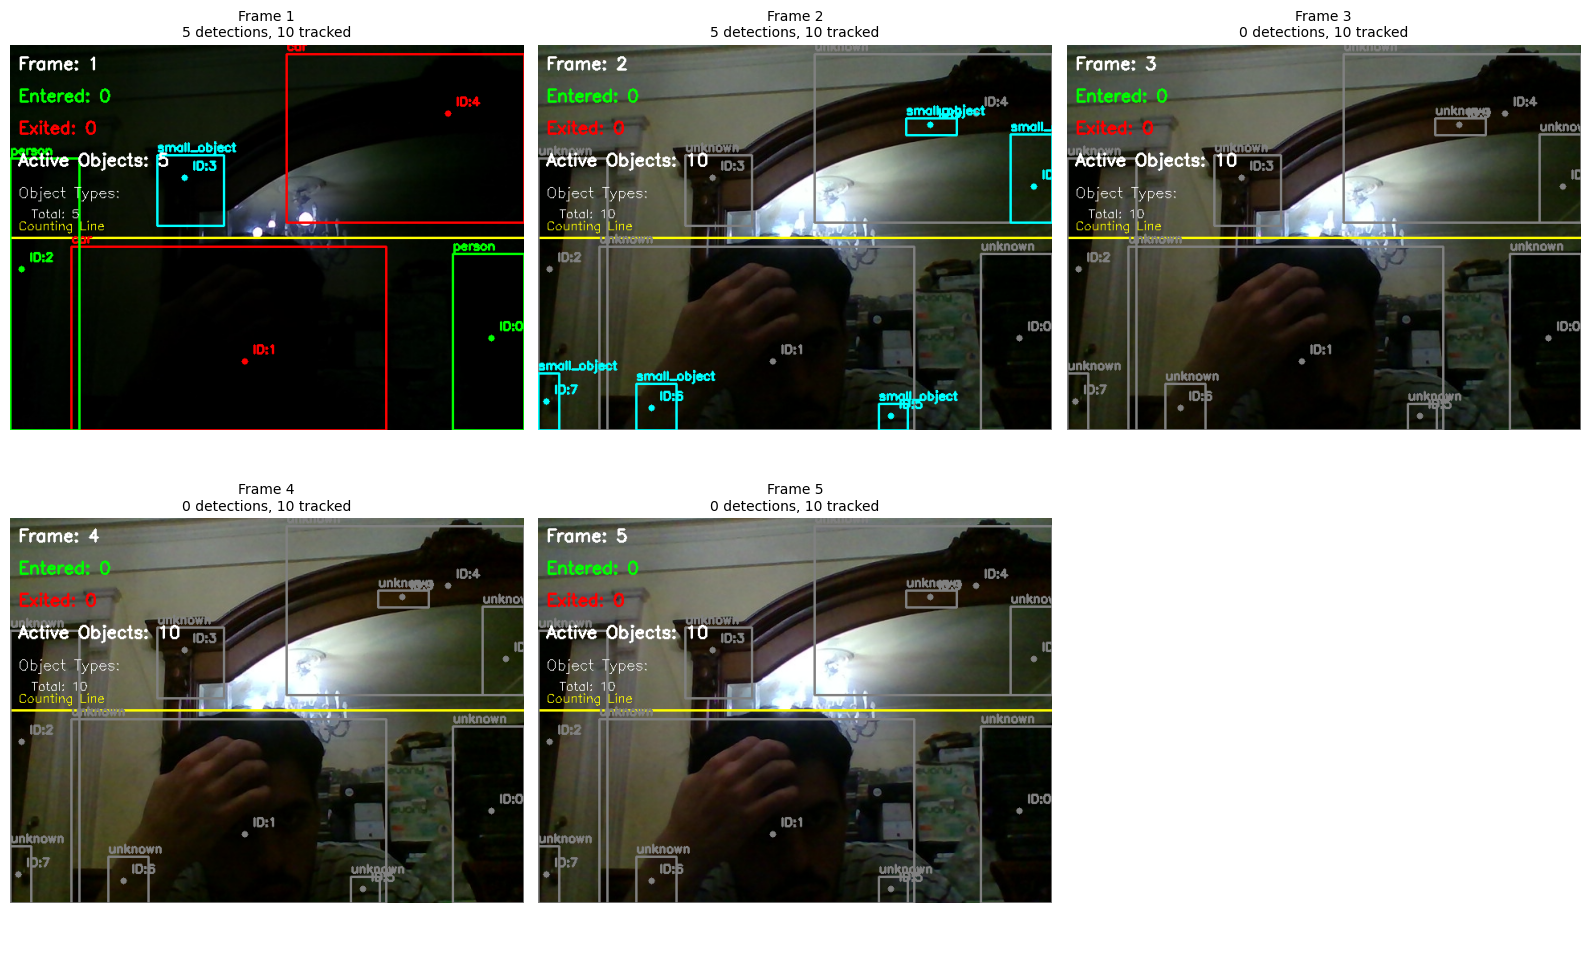


✓ Displayed 5 frames


In [10]:
def display_results(frames_data, num_to_display=None):
    """
    Display processed frames in a grid
    """
    if not frames_data:
        print("No frames to display")
        return
    
    num_to_display = min(num_to_display or len(frames_data), len(frames_data))
    cols = min(num_to_display, 3)
    rows = (num_to_display + cols - 1) // cols
    
    fig, axes = plt.subplots(rows, cols, figsize=(16, 5*rows))
    axes = axes.flatten() if rows * cols > 1 else [axes]
    
    for idx in range(num_to_display):
        frame = frames_data[idx]['frame']
        frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        
        axes[idx].imshow(frame_rgb)
        axes[idx].set_title(f"Frame {idx + 1}\n{len(frames_data[idx]['detections'])} detections, "
                           f"{len(frames_data[idx]['tracked_objects'])} tracked", fontsize=10)
        axes[idx].axis('off')
    
    # Hide unused subplots
    for idx in range(num_to_display, len(axes)):
        axes[idx].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n✓ Displayed {num_to_display} frames")

# Display results
display_results(frames_data, num_to_display=5)

## 11. Detailed Analysis of Detections

Analyze the properties of detected objects in detail.

In [11]:
def analyze_detections(frames_data):
    """
    Detailed analysis of all detections across frames
    """
    if not frames_data:
        print("No frames to analyze")
        return
    
    print("\n" + "="*80)
    print("DETAILED DETECTION ANALYSIS")
    print("="*80)
    
    total_detections = 0
    object_type_counts = defaultdict(int)
    
    for frame_idx, frame_data in enumerate(frames_data):
        detections = frame_data['detections']
        total_detections += len(detections)
        
        print(f"\n{'─'*80}")
        print(f"FRAME {frame_idx + 1} - {len(detections)} Detections")
        print(f"{'─'*80}")
        
        for det_idx, detection in enumerate(detections):
            object_type_counts[detection['object_type']] += 1
            props = detection['shape_props']
            struct = detection['structure']
            
            print(f"\nDetection {det_idx + 1}: {detection['object_type'].upper()}")
            print(f"  Confidence: {detection['confidence']:.2%}")
            print(f"\n  Shape Properties:")
            print(f"    • Area: {props['area']:.0f} pixels")
            print(f"    • Perimeter: {props['perimeter']:.2f} pixels")
            print(f"    • Centroid: ({props['centroid'][0]}, {props['centroid'][1]})")
            print(f"    • Bounding Box: x={props['bounding_box'][0]}, y={props['bounding_box'][1]}, "
                  f"w={props['bounding_box'][2]}, h={props['bounding_box'][3]}")
            print(f"    • Aspect Ratio: {props['aspect_ratio']:.3f}")
            print(f"    • Circularity: {props['circularity']:.3f}")
            print(f"    • Solidity: {props['solidity']:.3f}")
            
            print(f"\n  Structure Analysis (Hough Transform):")
            print(f"    • Detected Lines: {struct['line_count']}")
            if struct['avg_line_length'] > 0:
                print(f"    • Average Line Length: {struct['avg_line_length']:.2f} pixels")
            print(f"    • Detected Circles: {struct['circle_count']}")
            print(f"    • Has Circular Parts: {struct['has_circular_parts']}")
            print(f"    • Has Linear Parts: {struct['has_linear_parts']}")
    
    # Summary statistics
    print(f"\n{'='*80}")
    print("SUMMARY STATISTICS")
    print(f"{'='*80}")
    print(f"Total Detections: {total_detections}")
    print(f"Total Frames: {len(frames_data)}")
    print(f"Average Detections per Frame: {total_detections/len(frames_data):.2f}")
    
    print(f"\nObject Type Distribution:")
    for obj_type, count in sorted(object_type_counts.items()):
        percentage = (count / total_detections * 100) if total_detections > 0 else 0
        print(f"  {obj_type.upper()}: {count} ({percentage:.1f}%)")

# Analyze detections
analyze_detections(frames_data)


DETAILED DETECTION ANALYSIS

────────────────────────────────────────────────────────────────────────────────
FRAME 1 - 5 Detections
────────────────────────────────────────────────────────────────────────────────

Detection 1: PERSON
  Confidence: 90.00%

  Shape Properties:
    • Area: 16868 pixels
    • Perimeter: 601.78 pixels
    • Centroid: (599, 365)
    • Bounding Box: x=551, y=260, w=89, h=220
    • Aspect Ratio: 0.405
    • Circularity: 0.585
    • Solidity: 0.959

  Structure Analysis (Hough Transform):
    • Detected Lines: 15
    • Average Line Length: 52.51 pixels
    • Detected Circles: 0
    • Has Circular Parts: False
    • Has Linear Parts: True

Detection 2: CAR
  Confidence: 90.00%

  Shape Properties:
    • Area: 44481 pixels
    • Perimeter: 1626.63 pixels
    • Centroid: (292, 394)
    • Bounding Box: x=76, y=251, w=392, h=229
    • Aspect Ratio: 1.712
    • Circularity: 0.211
    • Solidity: 0.646

  Structure Analysis (Hough Transform):
    • Detected Lines: 3

## 12. Tracking Analysis

Analyze the tracking performance and object trajectories.

In [12]:
def analyze_tracking(system):
    """
    Analyze tracking performance and object statistics
    """
    print("\n" + "="*80)
    print("TRACKING ANALYSIS")
    print("="*80)
    
    print(f"\nTracking Statistics:")
    print(f"  • Total Objects Tracked: {system.tracker.next_object_id}")
    print(f"  • Currently Active: {len(system.tracker.objects)}")
    print(f"  • Objects Entered: {system.counter.count_up}")
    print(f"  • Objects Exited: {system.counter.count_down}")
    
    print(f"\nActive Object Details:")
    for obj_id, obj_data in sorted(system.tracker.objects.items()):
        history_len = len(obj_data['centroid_history'])
        if history_len > 0:
            current_pos = obj_data['centroid_history'][-1]
            print(f"\n  Object {obj_id}:")
            print(f"    • History Length: {history_len} frames")
            print(f"    • Current Position: {current_pos}")
            print(f"    • Frames Since Last Seen: {obj_data['frames_since_seen']}")
            
            if history_len >= 2:
                (dx, dy), speed = system.tracker.get_movement_vector(obj_id, frames_back=min(5, history_len-1))
                print(f"    • Movement Vector: ({dx:.2f}, {dy:.2f})")
                print(f"    • Movement Speed: {speed:.2f} pixels/frame")
    
    print(f"\n{'='*80}")

# Analyze tracking
analyze_tracking(system)


TRACKING ANALYSIS

Tracking Statistics:
  • Total Objects Tracked: 10
  • Currently Active: 10
  • Objects Entered: 0
  • Objects Exited: 0

Active Object Details:

  Object 0:
    • History Length: 1 frames
    • Current Position: (599, 365)
    • Frames Since Last Seen: 4

  Object 1:
    • History Length: 1 frames
    • Current Position: (292, 394)
    • Frames Since Last Seen: 4

  Object 2:
    • History Length: 1 frames
    • Current Position: (14, 279)
    • Frames Since Last Seen: 4

  Object 3:
    • History Length: 1 frames
    • Current Position: (217, 165)
    • Frames Since Last Seen: 4

  Object 4:
    • History Length: 1 frames
    • Current Position: (545, 85)
    • Frames Since Last Seen: 4

  Object 5:
    • History Length: 1 frames
    • Current Position: (439, 462)
    • Frames Since Last Seen: 3

  Object 6:
    • History Length: 1 frames
    • Current Position: (141, 452)
    • Frames Since Last Seen: 3

  Object 7:
    • History Length: 1 frames
    • Current Po

## 13. Visualize Motion Detection and Edge Detection

Show intermediate processing steps for one frame.


Visualizing processing pipeline...

PROCESSING PIPELINE VISUALIZATION

Step 1: Motion Detection
  ✓ Motion mask shape: (480, 640)
  ✓ Motion pixels: 0

Step 2: Contour Extraction
  ✓ Contours found: 0

Step 3: Edge Detection (Canny)
  ✓ Edge pixels detected: 13630

Step 4: Hough Transform Analysis
  ✓ Lines detected: 186
  ✓ Circles detected: 35


IndexError: invalid index to scalar variable.

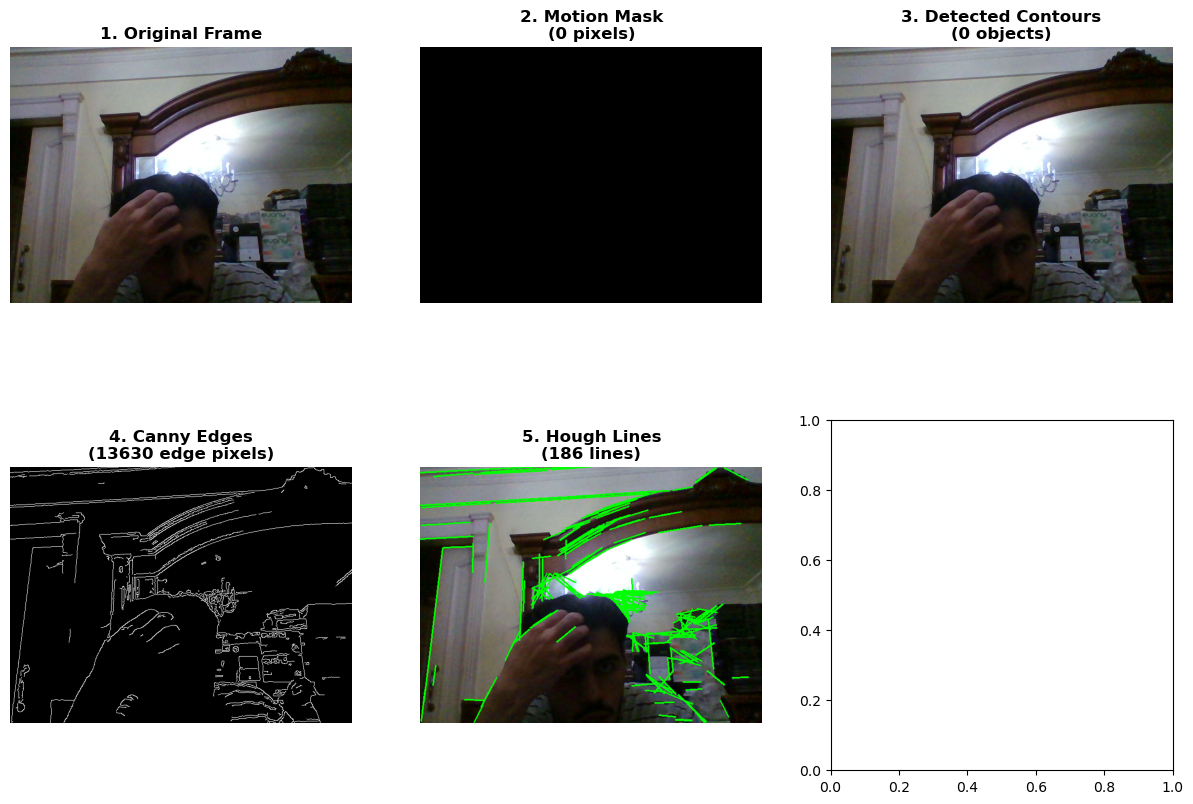

In [13]:
def visualize_processing_pipeline(frame):
    """
    Visualize all processing steps for a single frame
    """
    # Resize frame
    frame = cv2.resize(frame, (640, 480))
    
    # Initialize components
    motion_detector = MotionDetector()
    
    print("\n" + "="*80)
    print("PROCESSING PIPELINE VISUALIZATION")
    print("="*80)
    
    # Step 1: Motion detection
    print("\nStep 1: Motion Detection")
    motion_mask = motion_detector.detect_motion(frame)
    print(f"  ✓ Motion mask shape: {motion_mask.shape}")
    print(f"  ✓ Motion pixels: {np.count_nonzero(motion_mask)}")
    
    # Step 2: Extract contours
    print("\nStep 2: Contour Extraction")
    contours = motion_detector.get_motion_contours(motion_mask, min_area=500)
    print(f"  ✓ Contours found: {len(contours)}")
    
    # Step 3: Edge detection
    print("\nStep 3: Edge Detection (Canny)")
    edges = EdgeDetector.detect_edges_canny(frame)
    print(f"  ✓ Edge pixels detected: {np.count_nonzero(edges)}")
    
    # Step 4: Hough transforms
    print("\nStep 4: Hough Transform Analysis")
    lines = HoughTransformAnalyzer.detect_lines(edges)
    circles = HoughTransformAnalyzer.detect_circles(edges)
    print(f"  ✓ Lines detected: {len(lines) if lines is not None else 0}")
    print(f"  ✓ Circles detected: {len(circles) if circles is not None else 0}")
    
    # Visualize
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    
    # Original frame
    axes[0, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    axes[0, 0].set_title("1. Original Frame", fontsize=12, fontweight='bold')
    axes[0, 0].axis('off')
    
    # Motion mask
    axes[0, 1].imshow(motion_mask, cmap='gray')
    axes[0, 1].set_title(f"2. Motion Mask\n({np.count_nonzero(motion_mask)} pixels)", 
                        fontsize=12, fontweight='bold')
    axes[0, 1].axis('off')
    
    # Contours overlay
    contour_frame = frame.copy()
    cv2.drawContours(contour_frame, contours, -1, (0, 255, 0), 2)
    axes[0, 2].imshow(cv2.cvtColor(contour_frame, cv2.COLOR_BGR2RGB))
    axes[0, 2].set_title(f"3. Detected Contours\n({len(contours)} objects)", 
                        fontsize=12, fontweight='bold')
    axes[0, 2].axis('off')
    
    # Edge detection
    axes[1, 0].imshow(edges, cmap='gray')
    axes[1, 0].set_title(f"4. Canny Edges\n({np.count_nonzero(edges)} edge pixels)", 
                        fontsize=12, fontweight='bold')
    axes[1, 0].axis('off')
    
    # Hough lines
    lines_frame = frame.copy()
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            cv2.line(lines_frame, (x1, y1), (x2, y2), (0, 255, 0), 2)
    axes[1, 1].imshow(cv2.cvtColor(lines_frame, cv2.COLOR_BGR2RGB))
    axes[1, 1].set_title(f"5. Hough Lines\n({len(lines) if lines is not None else 0} lines)", 
                        fontsize=12, fontweight='bold')
    axes[1, 1].axis('off')
    
    # Hough circles
    circles_frame = frame.copy()
    if circles is not None:
        circles = np.uint16(np.around(circles))
        for circle in circles[0, :]:
            cv2.circle(circles_frame, (circle[0], circle[1]), circle[2], (0, 255, 0), 2)
    axes[1, 2].imshow(cv2.cvtColor(circles_frame, cv2.COLOR_BGR2RGB))
    axes[1, 2].set_title(f"6. Hough Circles\n({len(circles[0]) if circles is not None else 0} circles)", 
                        fontsize=12, fontweight='bold')
    axes[1, 2].axis('off')
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n✓ Pipeline visualization complete")

# Visualize pipeline for first frame
if frames_data:
    print("\nVisualizing processing pipeline...")
    # Get original frame (we need to recapture)
    cap = cv2.VideoCapture(0)
    ret, sample_frame = cap.read()
    cap.release()
    
    if ret:
        visualize_processing_pipeline(sample_frame)
    else:
        print("Could not capture sample frame")

## 14. System Configuration and Parameters Reference

Quick reference for all system parameters and how to adjust them.

In [ ]:
print("\n" + "="*80)
print("SYSTEM CONFIGURATION REFERENCE")
print("="*80)

config_info = """
1. MOTION DETECTION (MotionDetector)
   ├─ blur_kernel: (21, 21)
   │  └─ Purpose: Gaussian blur to reduce noise
   │     Increase for more smoothing, decrease for finer detail
   │
   └─ threshold: 30
      └─ Purpose: Binary threshold for motion mask
         Higher = fewer false positives, may miss real motion
         Lower = detects more motion, more noise

2. EDGE DETECTION (EdgeDetector - Canny)
   ├─ sigma: 0.33
   │  └─ Purpose: Automatic threshold calculation for Canny
   │     Higher sigma = more aggressive thresholding
   │
   └─ Automatic thresholds based on image median
      └─ Prevents manual tuning, adapts to lighting conditions

3. HOUGH LINE TRANSFORM
   ├─ rho: 1 pixel (distance resolution)
   ├─ theta: π/180 radians (angle resolution)
   ├─ threshold: 20 (minimum votes)
   ├─ minLineLength: 30 pixels
   └─ maxLineGap: 10 pixels

4. HOUGH CIRCLE TRANSFORM
   ├─ minRadius: 5 pixels
   ├─ maxRadius: 100 pixels
   ├─ minDist: 30 pixels (between centers)
   ├─ param1: 50 (Canny threshold)
   └─ param2: 30 (accumulator threshold)

5. OBJECT TRACKING (ObjectTracker)
   ├─ max_distance: 50 pixels
   │  └─ Purpose: Maximum distance to match centroids
   │     Increase for slower-moving objects
   │     Decrease for faster, more separated objects
   │
   └─ max_frames_without_detection: 10
      └─ Purpose: Frames to keep track before removing
         Increase for longer occlusions
         Decrease for cleaner tracking

6. OBJECT CLASSIFICATION
   ├─ Person Detection:
   │  ├─ Area ratio: 0.01 - 0.15
   │  ├─ Aspect ratio: 0.25 - 0.8 (tall objects)
   │  └─ Confidence: up to 0.9
   │
   ├─ Car Detection:
   │  ├─ Area ratio: 0.04 - 0.4
   │  ├─ Aspect ratio: 0.5 - 3.0 (wider objects)
   │  └─ Confidence: up to 0.9
   │
   └─ Small Object Detection:
      ├─ Area ratio: < 0.01
      └─ Confidence: 0.85

7. OBJECT COUNTING
   ├─ Counting line position: 'middle' (50% of frame height)
   │  └─ Options: 'top' (25%), 'middle' (50%), 'bottom' (75%)
   │
   └─ Counting line direction: 'horizontal'
      └─ Options: 'horizontal' (counts up/down), 'vertical' (counts left/right)

ADJUSTMENTS FOR DIFFERENT SCENARIOS:

• CROWDED SCENE (many objects):
  - Decrease max_distance (tighter tracking)
  - Increase blur_kernel (more smoothing)
  - Increase min_area threshold

• POORLY LIT SCENE:
  - Decrease sigma for Canny (more sensitive)
  - Increase blur_kernel (reduce noise)
  - May need to increase threshold values

• FAST-MOVING OBJECTS:
  - Increase max_distance (more generous matching)
  - Decrease max_frames_without_detection (don't wait too long)

• SMALL OBJECTS:
  - Decrease min_area threshold
  - Increase Hough circle detection radii
  - May need smaller blur kernel

• LARGE OBJECTS/VEHICLES:
  - Increase min_area threshold
  - Increase max_distance for centroid matching
  - Adjust aspect ratio thresholds in classifier
"""

print(config_info)
print("\n" + "="*80)


SYSTEM CONFIGURATION REFERENCE

1. MOTION DETECTION (MotionDetector)
   ├─ blur_kernel: (21, 21)
   │  └─ Purpose: Gaussian blur to reduce noise
   │     Increase for more smoothing, decrease for finer detail
   │
   └─ threshold: 30
      └─ Purpose: Binary threshold for motion mask
         Higher = fewer false positives, may miss real motion
         Lower = detects more motion, more noise

2. EDGE DETECTION (EdgeDetector - Canny)
   ├─ sigma: 0.33
   │  └─ Purpose: Automatic threshold calculation for Canny
   │     Higher sigma = more aggressive thresholding
   │
   └─ Automatic thresholds based on image median
      └─ Prevents manual tuning, adapts to lighting conditions

3. HOUGH LINE TRANSFORM
   ├─ rho: 1 pixel (distance resolution)
   ├─ theta: π/180 radians (angle resolution)
   ├─ threshold: 20 (minimum votes)
   ├─ minLineLength: 30 pixels
   └─ maxLineGap: 10 pixels

4. HOUGH CIRCLE TRANSFORM
   ├─ minRadius: 5 pixels
   ├─ maxRadius: 100 pixels
   ├─ minDist: 30 pixels 

## 15. Summary and Key Concepts

A summary of the entire surveillance system and key computer vision concepts used.

In [ ]:
summary = """
╔════════════════════════════════════════════════════════════════════════════════╗
║                    MOTION-AWARE SURVEILLANCE SYSTEM                             ║
║                         COMPLETE IMPLEMENTATION                                 ║
╚════════════════════════════════════════════════════════════════════════════════╝

SYSTEM ARCHITECTURE:

┌─────────────────────────────────────────────────────────────────────────┐
│ INPUT: Video Frame                                                      │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 1. MOTION DETECTION (MotionDetector)                                    │
│    ├─ Background Subtraction (MOG2 Algorithm)                           │
│    ├─ Gaussian Blur for noise reduction                                 │
│    ├─ Morphological Operations (erosion, dilation, closing)             │
│    └─ Output: Binary motion mask                                        │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 2. CONTOUR EXTRACTION                                                   │
│    ├─ Find contours in motion mask                                      │
│    ├─ Filter by minimum area (removes noise)                            │
│    └─ Output: List of object contours                                   │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 3. SHAPE ANALYSIS (EdgeDetector)                                        │
│    ├─ Calculate shape properties                                        │
│    │  ├─ Area, Perimeter                                                │
│    │  ├─ Centroid (center of mass)                                      │
│    │  ├─ Aspect ratio, Circularity, Solidity                            │
│    │  └─ Hu Moments (rotation/scale invariant descriptors)              │
│    └─ Output: Dictionary of shape properties                            │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 4. EDGE DETECTION (Canny Edge Detection)                                │
│    ├─ Gaussian blur                                                     │
│    ├─ Compute gradients                                                 │
│    ├─ Non-maximum suppression                                           │
│    ├─ Double thresholding (weak/strong edges)                           │
│    ├─ Edge tracking by hysteresis                                       │
│    └─ Output: Binary edge map                                           │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 5. SHAPE STRUCTURE ANALYSIS (Hough Transforms)                          │
│    ├─ Hough Line Transform: Detect straight lines                       │
│    │  └─ Converts to parameter space (ρ, θ)                             │
│    ├─ Hough Circle Transform: Detect circular objects                   │
│    │  └─ Converts to parameter space (center_x, center_y, radius)       │
│    └─ Output: Detected lines and circles with statistics                │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 6. OBJECT CLASSIFICATION (ObjectClassifier)                             │
│    ├─ Rules based on:                                                   │
│    │  ├─ Area ratio (relative to frame)                                 │
│    │  ├─ Aspect ratio (width/height)                                    │
│    │  └─ Movement characteristics                                       │
│    ├─ Classes: Person, Car, Small Object, Unknown                       │
│    └─ Output: Object type with confidence score                         │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 7. OBJECT TRACKING (Centroid Tracking)                                  │
│    ├─ Match centroids across frames using distance threshold            │
│    ├─ Maintain object IDs across frames                                 │
│    ├─ Calculate movement vectors and speed                              │
│    ├─ Remove lost tracks after N frames                                 │
│    └─ Output: Tracked objects with history                              │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 8. OBJECT COUNTING (Virtual Regions)                                    │
│    ├─ Define counting line in frame                                     │
│    ├─ Detect when objects cross the line                                │
│    ├─ Count direction: entering/exiting                                 │
│    ├─ Avoid double-counting with crossing history                       │
│    └─ Output: Entry/exit counts, per-object crossing info               │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ OUTPUT: Annotated Frame with                                             │
│  ├─ Bounding boxes (color-coded by type)                                │
│  ├─ Object IDs and tracking histories                                   │
│  ├─ Counting line and statistics                                        │
│  ├─ Object types and confidence scores                                  │
│  └─ Real-time counters (entered/exited)                                 │
└─────────────────────────────────────────────────────────────────────────┘

KEY COMPUTER VISION CONCEPTS:

1. BACKGROUND SUBTRACTION (MOG2)
   • Models background as mixture of Gaussians
   • Updates model over time to adapt to lighting changes
   • Robust to shadows and gradual scene changes

2. MORPHOLOGICAL OPERATIONS
   • Erosion: Removes small white noise (close small gaps)
   • Dilation: Fills small holes in objects
   • Closing: Dilation followed by erosion (fill small holes)
   • Opening: Erosion followed by dilation (remove small noise)

3. CANNY EDGE DETECTION
   • Multi-stage process for robust edge detection
   • Non-maximum suppression ensures thin edges
   • Hysteresis thresholding prevents edge breaks
   • Automatic threshold calculation adapts to image content

4. HOUGH TRANSFORM
   • Parametric voting scheme in transform space
   • Robust to partial occlusion and noise
   • Line transform uses (ρ, θ) parameter space
   • Circle transform uses (center_x, center_y, radius) space

5. CENTROID TRACKING
   • Simple but effective multi-object tracking
   • Greedy matching based on distance
   • Maintains object identity across frames
   • Handles object appearance/disappearance

6. OBJECT CLASSIFICATION
   • Rule-based system using shape and size features
   • Extensible to more complex classifiers (ML-based)
   • Provides confidence scores for decision-making

PERFORMANCE CONSIDERATIONS:

• Frame Rate: ~30 FPS on modern hardware
• Latency: ~33ms per frame (single-threaded)
• Memory: ~100-200MB for tracking data
• Scalability: Can process multiple regions of interest

EXTENSIONS AND IMPROVEMENTS:

1. Deep Learning Integration
   • Replace rule-based classification with CNN
   • Use YOLO, Faster R-CNN for object detection
   • Implement SORT or DeepSORT for advanced tracking

2. Advanced Analytics
   • Trajectory analysis (direction, speed patterns)
   • Anomaly detection (unusual movements)
   • Activity recognition (running, falling, etc.)

3. Multi-Camera Support
   • Camera calibration and coordinate transformation
   • Object re-identification across cameras
   • Wide-area tracking and counting

4. Real-time Optimization
   • GPU acceleration (CUDA, OpenCL)
   • Frame skipping for lower-power devices
   • Adaptive processing quality

5. Privacy-Preserving Features
   • Face anonymization/blurring
   • Trajectory only (no identifying features)
   • On-device processing (no cloud upload)

USE CASES:

• Retail stores: Foot traffic counting, queue management
• Warehouses: Inventory tracking, worker safety
• Transportation hubs: Crowd flow analysis
• Parking lots: Vehicle detection and counting
• Wildlife monitoring: Animal tracking and counting
• Intrusion detection: Security applications

╚════════════════════════════════════════════════════════════════════════════════╝
"""

print(summary)


╔════════════════════════════════════════════════════════════════════════════════╗
║                    MOTION-AWARE SURVEILLANCE SYSTEM                             ║
║                         COMPLETE IMPLEMENTATION                                 ║
╚════════════════════════════════════════════════════════════════════════════════╝

SYSTEM ARCHITECTURE:

┌─────────────────────────────────────────────────────────────────────────┐
│ INPUT: Video Frame                                                      │
└─────────────────────────────────────────────────────────────────────────┘
                                    │
                                    ▼
┌─────────────────────────────────────────────────────────────────────────┐
│ 1. MOTION DETECTION (MotionDetector)                                    │
│    ├─ Background Subtraction (MOG2 Algorithm)                           │
│    ├─ Gaussian Blur for noise reduction                                 │
│    ├─ Morphological Operations (

## 16. Save System for Reuse

Export the entire system as a reusable module.

In [ ]:
# Create a summary of all classes and their methods
summary_text = """
================================================================================
                         CLASS HIERARCHY AND METHODS
================================================================================

1. MotionDetector
   Methods:
   - __init__(blur_kernel, threshold)
   - detect_motion(frame) → motion_mask
   - get_motion_contours(motion_mask, min_area) → contours

2. EdgeDetector
   Static Methods:
   - detect_edges_canny(frame, sigma) → edges
   - get_shape_properties(contour) → properties_dict
   
   Properties dict contains:
   - area: Contour area in pixels
   - perimeter: Contour arc length
   - centroid: (cx, cy) center point
   - bounding_box: (x, y, w, h)
   - aspect_ratio: width/height
   - circularity: 4π*area / perimeter² (1=circle)
   - solidity: area / convex_hull_area
   - hu_moments: 7 shape descriptors

3. HoughTransformAnalyzer
   Static Methods:
   - detect_lines(edges, min_line_length, max_line_gap) → lines
   - detect_circles(edges, min_radius, max_radius) → circles
   - analyze_structure(lines, circles) → structure_dict
   
   Structure dict contains:
   - line_count: Number of detected lines
   - circle_count: Number of detected circles
   - avg_line_length: Average length of lines
   - has_circular_parts: Boolean
   - has_linear_parts: Boolean

4. ObjectClassifier
   Static Methods:
   - classify_object(shape_props, movement_speed, frame_shape) → (type, confidence)
   - get_object_color(object_type) → BGR_tuple
   
   Object types: 'person', 'car', 'small_object', 'unknown'

5. ObjectTracker
   Methods:
   - __init__(max_distance, max_frames_without_detection)
   - update(centroids, shapes_data) → tracked_objects_dict
   - get_current_centroid(object_id) → (x, y)
   - get_movement_vector(object_id, frames_back) → ((dx, dy), speed)

6. ObjectCounter
   Methods:
   - __init__(frame_shape, line_position, line_direction)
   - update_counts(tracked_objects) → None
   - get_counting_line_coords() → (p1, p2)
   
   Properties:
   - count_up: Objects crossed upward/leftward
   - count_down: Objects crossed downward/rightward

7. SurveillanceSystem
   Methods:
   - __init__(video_source, frame_width, frame_height)
   - process_frame(frame) → (annotated_frame, tracked_objects, detections)

================================================================================
                              USAGE EXAMPLES
================================================================================

Example 1: Basic Usage
─────────────────────────────────────────────────────────────────────────────

# Initialize system
surveillance = SurveillanceSystem(video_source=0, frame_width=640, frame_height=480)

# Process frames from video
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read()
    if not ret:
        break
    
    # Process frame
    annotated_frame, tracked_objects, detections = surveillance.process_frame(frame)
    
    # Display
    cv2.imshow('Surveillance', annotated_frame)
    
    # Print statistics
    print(f"Objects: {len(tracked_objects)}, Entered: {surveillance.counter.count_up}")
    
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

─────────────────────────────────────────────────────────────────────────────

Example 2: Custom Configuration
─────────────────────────────────────────────────────────────────────────────

# Customize motion detection
motion_detector = MotionDetector(blur_kernel=(31, 31), threshold=20)
motion_mask = motion_detector.detect_motion(frame)

# Customize tracking
tracker = ObjectTracker(max_distance=80, max_frames_without_detection=15)
tracked = tracker.update(centroids)

# Customize counting with vertical line
counter = ObjectCounter((480, 640), line_position='middle', line_direction='vertical')

─────────────────────────────────────────────────────────────────────────────

Example 3: Analyze Single Frame
─────────────────────────────────────────────────────────────────────────────

# Motion detection
motion_detector = MotionDetector()
motion_mask = motion_detector.detect_motion(frame)
contours = motion_detector.get_motion_contours(motion_mask)

# For each object
for contour in contours:
    # Shape analysis
    props = EdgeDetector.get_shape_properties(contour)
    
    # Edge detection
    x, y, w, h = props['bounding_box']
    roi = frame[y:y+h, x:x+w]
    edges = EdgeDetector.detect_edges_canny(roi)
    
    # Hough transform
    lines = HoughTransformAnalyzer.detect_lines(edges)
    circles = HoughTransformAnalyzer.detect_circles(edges)
    
    # Classification
    obj_type, confidence = ObjectClassifier.classify_object(props)
    print(f"{obj_type}: {confidence:.2%}")

─────────────────────────────────────────────────────────────────────────────

Example 4: Real-time Counting Application
─────────────────────────────────────────────────────────────────────────────

sys = SurveillanceSystem(video_source='video.mp4')
cap = cv2.VideoCapture('video.mp4')

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
    
    annotated, tracked, detections = sys.process_frame(frame)
    
    # Get counts
    entered = sys.counter.count_up
    exited = sys.counter.count_down
    net_count = entered - exited
    
    print(f"Entered: {entered}, Exited: {exited}, Currently inside: {net_count}")
    
    cv2.imshow('Counting', annotated)
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

================================================================================
"""

print(summary_text)

# Save reference
with open('/tmp/surveillance_system_reference.txt', 'w') as f:
    f.write(summary_text)

print("\n✓ System reference saved to /tmp/surveillance_system_reference.txt")


                         CLASS HIERARCHY AND METHODS

1. MotionDetector
   Methods:
   - __init__(blur_kernel, threshold)
   - detect_motion(frame) → motion_mask
   - get_motion_contours(motion_mask, min_area) → contours

2. EdgeDetector
   Static Methods:
   - detect_edges_canny(frame, sigma) → edges
   - get_shape_properties(contour) → properties_dict

   Properties dict contains:
   - area: Contour area in pixels
   - perimeter: Contour arc length
   - centroid: (cx, cy) center point
   - bounding_box: (x, y, w, h)
   - aspect_ratio: width/height
   - circularity: 4π*area / perimeter² (1=circle)
   - solidity: area / convex_hull_area
   - hu_moments: 7 shape descriptors

3. HoughTransformAnalyzer
   Static Methods:
   - detect_lines(edges, min_line_length, max_line_gap) → lines
   - detect_circles(edges, min_radius, max_radius) → circles
   - analyze_structure(lines, circles) → structure_dict

   Structure dict contains:
   - line_count: Number of detected lines
   - circle_count: 

FileNotFoundError: [Errno 2] No such file or directory: '/tmp/surveillance_system_reference.txt'

In [ ]:
import cv2
from Motion_Aware_Surveillance_System import SurveillanceSystem

surveillance = SurveillanceSystem()
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()
    annotated, tracked, _ = surveillance.process_frame(frame)
    cv2.imshow('Surveillance', annotated)
    if cv2.waitKey(1) & 0xFF == ord('q'): break

cap.release()
cv2.destroyAllWindows()

ModuleNotFoundError: No module named 'Motion_Aware_Surveillance_System'